## Step 1 — Install dependencies

What is Playwright?

Playwright is an open-source browser automation framework developed by Microsoft.

It allows you to control web browsers using Python, JavaScript, Java, or C#.

You can use it to:

Scrape websites
Automate login
Fill forms
Download files
Test web applications
Capture screenshots
Handle JavaScript-heavy websites

In [1]:
!pip install playwright
!playwright install chromium #This installs the Chromium browser that Playwright controls.
!playwright install-deps chromium #This installs operating-system-level dependencies required by Chromium.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.5/47.5 MB 14.4 MB/s eta 0:00:00
175.4 MiB [] 0% 0.0s175.4 MiB [] 0% 24.6s175.4 MiB [] 0% 15.6s175.4 MiB [] 0% 14.1s175.4 MiB [] 1% 6.5s175.4 MiB [] 2% 4.7s175.4 MiB [] 2% 4.8s175.4 MiB [] 2% 4.6s175.4 MiB [] 3% 4.3s175.4 MiB [] 3% 4.2s175.4 MiB [] 3% 4.6s175.4 MiB [] 4% 4.0s175.4 MiB [] 5% 3.7s175.4 MiB [] 6% 3.6s175.4 MiB [] 7% 3.4s175.4 MiB [] 7% 3.5s175.4 MiB [] 8% 3.6s175.4 MiB [] 8% 3.8s175.4 MiB [] 9% 3.5s175.4 MiB [] 10% 3.3s175.4 MiB [] 11% 3.1s175.4 MiB [] 12% 3.0s175.4 MiB [] 13% 2.8s175.4 MiB [] 14% 2.7s175.4 MiB [] 14% 2.8s175.4 MiB [] 15% 2.6s175.4 MiB [] 16% 2.5s175.4 MiB [] 17% 2.4s175.4 MiB [] 18% 2.3s175.4 MiB [] 19% 2.3s175.4 MiB [] 20% 2.3s175.4 MiB [] 21% 2.2s175.4 MiB [] 22% 2.2s175.4 MiB [] 22% 2.3s175.4 MiB [] 22% 2.4s175.4 MiB [] 23% 2.4s175.4 MiB [] 23% 2.3s175.4 MiB [] 24% 2.3s175.4 MiB [] 25% 2.2s175.4 MiB [] 26% 2.1s175.4 MiB [] 27% 2.1s175.4 MiB [] 28% 2.1s175.4 MiB [] 28% 2.0s175.4 MiB [] 29% 2.0s175.4 MiB [] 

## Step 2 — Imports and configuration

In [2]:
import json
import math
import os
import sqlite3
from datetime import datetime, timezone

import pandas as pd
from playwright.async_api import async_playwright

PAGE_URL = "https://www.meteoblue.com/en/weather/forecast/multimodel/chand%c4%abpur_india_1274740"
DB_PATH  = "meteoblue_forecast.sqlite"


## Step 3 — Capture Meteoblue multimodel JSON via Playwright

In [3]:
async def capture_meteoblue_data(page_url):
    async with async_playwright() as p:#When the block ends, Playwright automatically shuts down.
        browser = await p.chromium.launch(headless=True)
        page    = await browser.new_page()
        captured = {}

        async def handle_response(response):
            if "my.meteoblue.com/images/meteogram_multimodel" in response.url:
                captured["url"] = response.url
                try:
                    captured["data"] = await response.json()
                except Exception:
                    text = await response.text()
                    captured["data"] = json.loads(text)

        page.on("response", handle_response)
        await page.goto(page_url, wait_until="networkidle", timeout=90000)
        await page.wait_for_timeout(5000)
        await browser.close()

    return captured["url"], captured["data"]


data_url, data = await capture_meteoblue_data(PAGE_URL)
print("Captured URL:", data_url)
print("Top-level keys:", list(data.keys()) if isinstance(data, dict) else type(data))

Captured URL: https://my.meteoblue.com/images/meteogram_multimodel?temperature_units=F&windspeed_units=mph&precipitation_units=inch&darkmode=false&iso2=in&lat=21.4441&lon=87.0283&asl=12&tz=Asia%2FKolkata&forecast_days=3&dpi=72&apikey=n4UGDLso3gE6m2YI&lang=en&location_name=Chand%C4%ABpur&ts=1782258645&format=highcharts&domains=IFS025&domains=ICON&domains=GFS05&domains=MFGLOBAL&domains=UMGLOBAL10&domains=GEM15&domains=AIFS025&domains=IFSHRES&domains=NEMSGLOBAL&domains=NEMSIN&domains=NEMSGLOBAL_E&sig=d70da4a81c0f1930b92b05dc39ab229e
Top-level keys: ['isMultimodel', 'disableLegendToggle', 'chart', 'title', 'subtitle', 'exporting', 'navigation', 'tooltip', 'legend', 'credits', 'caption', 'xAxis', 'yAxis', 'plotOptions', 'series', 'boost']


## Step 4 — Inspect raw JSON (quick preview)

In [4]:
print(json.dumps(data, indent=2)[:3000])

{
  "isMultimodel": true,
  "disableLegendToggle": true,
  "chart": {
    "zooming": {
      "type": "x"
    },
    "backgroundColor": "transparent",
    "spacingTop": 5,
    "spacingBottom": 0,
    "marginLeft": 90,
    "height": 1540.0
  },
  "title": {
    "text": "Chand\u012bpur",
    "useHTML": false,
    "align": "left",
    "style": {
      "fontSize": "1.6em",
      "color": "black"
    }
  },
  "subtitle": {
    "text": "21.44\u00b0N, 87.03\u00b0E (12 m asl)",
    "style": {
      "fontSize": "1.2em",
      "color": "black"
    },
    "useHTML": false,
    "align": "left"
  },
  "exporting": {
    "enabled": false
  },
  "navigation": {
    "menuStyle": {
      "background": "#FFFFFF"
    },
    "menuItemStyle": {
      "color": "black"
    }
  },
  "tooltip": {
    "followPointer": true,
    "backgroundColor": "#FFFFFF",
    "style": {
      "color": "black",
      "fontSize": "1em"
    }
  },
  "legend": {
    "enabled": false
  },
  "credits": {
    "enabled": false
  },
  

## Step 5 — Map yAxis indices to field names

In [5]:
def axis_to_field(axis_title):
    title = str(axis_title).lower()
    if "temperature"    in title: return "temperature_c"
    if "precipitation"  in title: return "precipitation_mm_per_hour"
    if "wind speed"     in title: return "wind_speed_ms"
    if "wind direction" in title: return "wind_direction_degrees"
    if "humidity"       in title: return "relative_humidity_percent"
    return None


axis_map = {}
for i, axis in enumerate(data["yAxis"]):
    title = axis.get("title", {}).get("text")
    axis_map[i] = axis_to_field(title)
    print(i, title, "=>", axis_map[i])

precip_axis_index = next(
    (i for i, f in axis_map.items() if f == "precipitation_mm_per_hour"),
    1
)


0 Temperature (°F) => temperature_c
1 Precipitation (inch/h) => precipitation_mm_per_hour
2 AIFS-25<br/>43m asl => None
3 GEM-15<br/>15m asl => None
4 GFS-40<br/>7m asl => None
5 ICON-12<br/>11m asl => None
6 IFS-20<br/>43m asl => None
7 IFS-HRES<br/>1m asl => None
8 ARPEGE-25<br/>6m asl => None
9 NEMS-30<br/>10m asl => None
10 NEMS2-30<br/>10m asl => None
11 NEMS-10<br/>2m asl => None
12 UKMO-10<br/>4m asl => None
13 Wind speed (mph) => wind_speed_ms
14 Wind direction => wind_direction_degrees
15 Relative Humidity (%) => relative_humidity_percent


## Step 6 — Build per-model weather rows from series data

In [6]:
#  Unit-conversion helpers
def f_to_c(v):   return round((v - 32) * 5 / 9, 2) if v is not None else None
def iph_to_mmph(v): return round(v * 25.4, 4)      if v is not None else None
def mph_to_ms(v):   return round(v * 0.44704, 4)   if v is not None else None


def ms_to_utc(x_value):
    # Convert a millisecond Unix timestamp to an ISO-8601 UTC string.
    if isinstance(x_value, (int, float)) and x_value > 10_000_000_000:
        return datetime.fromtimestamp(x_value / 1000, tz=timezone.utc).isoformat()
    return None


rows = {}

for series in data["series"]:
    model_name  = series.get("name")
    axis_index  = series.get("yAxis", 0)
    field       = axis_map.get(axis_index)

    if field is None:
        continue

    for point in series.get("data", []):
        if isinstance(point, list):
            x_value = point[0]
            y_value = point[1] if len(point) > 1 else None
        elif isinstance(point, dict):
            x_value = point.get("x")
            y_value = point.get("y")
        else:
            continue

        if y_value is None:
            continue

        #  Apply unit conversions at ingestion
        if field == "temperature_c":
            y_value = f_to_c(y_value)
        elif field == "precipitation_mm_per_hour":
            y_value = iph_to_mmph(y_value)
        elif field == "wind_speed_ms":
            y_value = mph_to_ms(y_value)

        key = (model_name, x_value)
        if key not in rows:
            rows[key] = {
                "model_name":                model_name,
                "forecast_time_utc":         ms_to_utc(x_value),
                "x_timestamp_ms":            int(x_value) if isinstance(x_value, (int, float)) else x_value,
                "temperature_c":             None,
                "precipitation_mm_per_hour": None,
                "wind_speed_ms":             None,
                "wind_direction_degrees":    None,
                "relative_humidity_percent": None,
                "cloud_condition":           None,
                "cloud_icon_url":            None,
            }
        rows[key][field] = y_value

weather_df = pd.DataFrame(rows.values())
print("Shape:", weather_df.shape)
weather_df.head(20)


Shape: (949, 10)


,model_name,forecast_time_utc,x_timestamp_ms,temperature_c,precipitation_mm_per_hour,wind_speed_ms,wind_direction_degrees,relative_humidity_percent,cloud_condition,cloud_icon_url
0,AIFS025,2026-06-24T00:00:00+00:00,1782259200000,28.02,NaN,2.0251,237.0,84.0,None,None
1,AIFS025,2026-06-24T01:00:00+00:00,1782262800000,27.83,NaN,2.0698,236.0,85.0,None,None
2,AIFS025,2026-06-24T02:00:00+00:00,1782266400000,27.59,NaN,2.1369,235.0,86.0,None,None
3,AIFS025,2026-06-24T03:00:00+00:00,1782270000000,27.46,NaN,2.2218,234.0,86.0,None,None
4,AIFS025,2026-06-24T04:00:00+00:00,1782273600000,27.44,NaN,2.3559,233.0,86.0,None,None
5,AIFS025,2026-06-24T05:00:00+00:00,1782277200000,27.54,NaN,2.5034,232.0,86.0,None,None
6,AIFS025,2026-06-24T06:00:00+00:00,1782280800000,27.95,NaN,2.5615,231.0,84.0,None,None
7,AIFS025,2026-06-24T07:00:00+00:00,1782284400000,28.83,NaN,2.4542,231.0,81.0,None,None
8,AIFS025,2026-06-24T08:00:00+00:00,1782288000000,30.01,NaN,2.2531,231.0,76.0,None,None
9,AIFS025,2026-06-24T09:00:00+00:00,1782291600000,31.15,NaN,2.0609,230.0,72.0,None,None


## Step 7 — Extract cloud / weather-icon condition

In [7]:
# Full Meteoblue pictogram mapping
ICON_MAP = {
    "01_iday":   "Sunny",
    "01_inight": "Clear",
    "02_iday":   "Mainly sunny",
    "02_inight": "Mainly clear",
    "03_iday":   "Partly cloudy",
    "03_inight": "Partly cloudy (Night)",
    "04_iday":   "Overcast",
    "04_inight": "Overcast (Night)",
    "06_iday":   "Cloudy",
    "06_inight": "Cloudy (Night)",
    "07_iday":   "Rainy",
    "07_inight": "Rainy (Night)",
    "08_iday":   "Showers",
    "08_inight": "Showers (Night)",
}


def classify_icon(text):
    """Map a Meteoblue icon filename/URL to its official weather name."""
    text = str(text).lower()
    for key, label in ICON_MAP.items():
        if key.lower() in text:
            return label
    # Fallback: numeric-prefix only (no day/night distinction)
    for prefix, label in [
        ("01_", "Sunny/Clear"), ("02_", "Mainly sunny/clear"),
        ("03_", "Partly cloudy"), ("04_", "Overcast"),
        ("06_", "Cloudy"), ("07_", "Rainy"), ("08_", "Showers"),
    ]:
        if prefix in text:
            return label
    return None


cloud_rows = []
ICON_IDS   = ["01_", "02_", "03_", "04_", "06_", "07_", "08_"]

for series in data["series"]:
    series_text = json.dumps(series, ensure_ascii=False).lower()
    if not any(icon in series_text for icon in ICON_IDS):
        continue

    model_name = series.get("name")
    for point in series.get("data", []):
        if not isinstance(point, dict):
            continue
        x_value   = point.get("x")
        symbol    = point.get("marker", {}).get("symbol")
        condition = classify_icon(symbol)
        if condition is None:
            continue
        cloud_rows.append({
            "model_name":        model_name,
            "x_timestamp_ms":    int(x_value) if isinstance(x_value, (int, float)) else x_value,
            "forecast_time_utc": ms_to_utc(x_value),
            "cloud_condition":   condition,
            "cloud_icon_url":    symbol,
        })

cloud_df = pd.DataFrame(cloud_rows)
print("Cloud rows:", len(cloud_df))
cloud_df.head(20)


Cloud rows: 264


,model_name,x_timestamp_ms,forecast_time_utc,cloud_condition,cloud_icon_url
0,AIFS025,1782264600000,2026-06-24T01:30:00+00:00,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
1,AIFS025,1782275400000,2026-06-24T04:30:00+00:00,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
2,AIFS025,1782286200000,2026-06-24T07:30:00+00:00,Rainy,url(https://my.meteoblue.com/images/static/met...
3,AIFS025,1782297000000,2026-06-24T10:30:00+00:00,Rainy,url(https://my.meteoblue.com/images/static/met...
4,AIFS025,1782307800000,2026-06-24T13:30:00+00:00,Rainy,url(https://my.meteoblue.com/images/static/met...
5,AIFS025,1782318600000,2026-06-24T16:30:00+00:00,Rainy,url(https://my.meteoblue.com/images/static/met...
6,AIFS025,1782329400000,2026-06-24T19:30:00+00:00,Rainy,url(https://my.meteoblue.com/images/static/met...
7,AIFS025,1782340200000,2026-06-24T22:30:00+00:00,Rainy (Night),url(https://my.meteoblue.com/images/static/met...
8,AIFS025,1782351000000,2026-06-25T01:30:00+00:00,Partly cloudy (Night),url(https://my.meteoblue.com/images/static/met...
9,AIFS025,1782361800000,2026-06-25T04:30:00+00:00,Mainly clear,url(https://my.meteoblue.com/images/static/met...


## Step 8 — Merge weather and cloud data per model

In [8]:
weather_df["x_timestamp_ms"] = weather_df["x_timestamp_ms"].astype("int64")
cloud_df["x_timestamp_ms"]   = cloud_df["x_timestamp_ms"].astype("int64")

merged_parts = []

for model_name in weather_df["model_name"].dropna().unique():
    left  = weather_df[weather_df["model_name"] == model_name].copy()
    right = cloud_df[cloud_df["model_name"] == model_name].copy()

    left = left.drop(columns=["cloud_condition", "cloud_icon_url"], errors="ignore")

    if right.empty:
        merged_parts.append(left)
        continue

    merged = pd.merge_asof(
        left.sort_values("x_timestamp_ms"),
        right[["x_timestamp_ms", "cloud_condition", "cloud_icon_url"]].sort_values("x_timestamp_ms"),
        on="x_timestamp_ms",
        direction="nearest",
        tolerance=2 * 60 * 60 * 1000,   # 2-hour window
    )
    merged["model_name"] = model_name
    merged_parts.append(merged)

weather_df_final = pd.concat(merged_parts, ignore_index=True)
print("Shape after merge:", weather_df_final.shape)
weather_df_final.head(20)

Shape after merge: (949, 10)


,model_name,forecast_time_utc,x_timestamp_ms,temperature_c,precipitation_mm_per_hour,wind_speed_ms,wind_direction_degrees,relative_humidity_percent,cloud_condition,cloud_icon_url
0,AIFS025,2026-06-24T00:00:00+00:00,1782259200000,28.02,NaN,2.0251,237.0,84.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
1,AIFS025,2026-06-24T01:00:00+00:00,1782262800000,27.83,NaN,2.0698,236.0,85.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
2,AIFS025,2026-06-24T02:00:00+00:00,1782266400000,27.59,NaN,2.1369,235.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
3,AIFS025,2026-06-24T03:00:00+00:00,1782270000000,27.46,NaN,2.2218,234.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
4,AIFS025,2026-06-24T04:00:00+00:00,1782273600000,27.44,NaN,2.3559,233.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
5,AIFS025,2026-06-24T05:00:00+00:00,1782277200000,27.54,NaN,2.5034,232.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
6,AIFS025,2026-06-24T06:00:00+00:00,1782280800000,27.95,NaN,2.5615,231.0,84.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
7,AIFS025,2026-06-24T07:00:00+00:00,1782284400000,28.83,NaN,2.4542,231.0,81.0,Rainy,url(https://my.meteoblue.com/images/static/met...
8,AIFS025,2026-06-24T08:00:00+00:00,1782288000000,30.01,NaN,2.2531,231.0,76.0,Rainy,url(https://my.meteoblue.com/images/static/met...
9,AIFS025,2026-06-24T09:00:00+00:00,1782291600000,31.15,NaN,2.0609,230.0,72.0,Rainy,url(https://my.meteoblue.com/images/static/met...


## Step 9 — Fix precipitation via targeted axis extraction

In [9]:
precip_rows = []

for series in data["series"]:
    if series.get("yAxis", 0) != precip_axis_index:
        continue
    model_name = series.get("name")
    for point in series.get("data", []):
        if isinstance(point, list):
            x_value, y_value = (point[0], point[1] if len(point) > 1 else None)
        elif isinstance(point, dict):
            x_value, y_value = point.get("x"), point.get("y")
        else:
            continue
        if x_value is None or y_value is None:
            continue
        precip_rows.append({
            "precip_model_name":         model_name,
            "x_timestamp_ms":            int(x_value),
            "forecast_time_utc":         ms_to_utc(x_value),
            "precipitation_mm_per_hour": iph_to_mmph(y_value),  # inch/hr → mm/hr
        })

precip_df = pd.DataFrame(precip_rows)
print("Precip rows:", len(precip_df))

precip_unique = (
    precip_df.sort_values("x_timestamp_ms")
             .drop_duplicates(subset=["x_timestamp_ms"], keep="first")
)

weather_df_final["x_timestamp_ms"] = weather_df_final["x_timestamp_ms"].astype("int64")
weather_df_final = weather_df_final.drop(columns=["precipitation_mm_per_hour"], errors="ignore")

weather_df_final = pd.merge_asof(
    weather_df_final.sort_values("x_timestamp_ms"),
    precip_unique[["x_timestamp_ms", "precipitation_mm_per_hour", "precip_model_name"]]
                    .sort_values("x_timestamp_ms"),
    on="x_timestamp_ms",
    direction="nearest",
    tolerance=2 * 60 * 60 * 1000,
)

print("Shape after precip merge:", weather_df_final.shape)


Precip rows: 803
Shape after precip merge: (949, 11)


## Step 10 — Final clean-up and column selection

In [10]:
VALUE_COLS = [
    "temperature_c",
    "precipitation_mm_per_hour",
    "wind_speed_ms",
    "wind_direction_degrees",
    "relative_humidity_percent",
]

clean_final_df = (
    weather_df_final
    .loc[weather_df_final["model_name"] != "Models agreement"]
    .dropna(subset=VALUE_COLS, how="all")
    [[
        "model_name",
        "forecast_time_utc",
        "x_timestamp_ms",
        "temperature_c",
        "precipitation_mm_per_hour",
        "wind_speed_ms",
        "wind_direction_degrees",
        "relative_humidity_percent",
        "cloud_condition",
        "cloud_icon_url",
        "precip_model_name",
    ]]
    .sort_values(["model_name", "x_timestamp_ms"])
    .reset_index(drop=True)
)

print("Final shape:", clean_final_df.shape)
print("Null counts:\n", clean_final_df.isna().sum())
clean_final_df.head(50)


Final shape: (876, 11)
Null counts:
 model_name                    0
forecast_time_utc             0
x_timestamp_ms                0
temperature_c                 0
precipitation_mm_per_hour     0
wind_speed_ms                 0
wind_direction_degrees       73
relative_humidity_percent     0
cloud_condition              73
cloud_icon_url               73
precip_model_name             0
dtype: int64


,model_name,forecast_time_utc,x_timestamp_ms,temperature_c,precipitation_mm_per_hour,wind_speed_ms,wind_direction_degrees,relative_humidity_percent,cloud_condition,cloud_icon_url,precip_model_name
0,AIFS025,2026-06-24T00:00:00+00:00,1782259200000,28.02,1.4656,2.0251,237.0,84.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement
1,AIFS025,2026-06-24T01:00:00+00:00,1782262800000,27.83,0.0000,2.0698,236.0,85.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement
2,AIFS025,2026-06-24T02:00:00+00:00,1782266400000,27.59,0.0000,2.1369,235.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement
3,AIFS025,2026-06-24T03:00:00+00:00,1782270000000,27.46,0.0000,2.2218,234.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement
4,AIFS025,2026-06-24T04:00:00+00:00,1782273600000,27.44,0.0000,2.3559,233.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement
5,AIFS025,2026-06-24T05:00:00+00:00,1782277200000,27.54,0.0000,2.5034,232.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement
6,AIFS025,2026-06-24T06:00:00+00:00,1782280800000,27.95,0.0000,2.5615,231.0,84.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement
7,AIFS025,2026-06-24T07:00:00+00:00,1782284400000,28.83,0.0000,2.4542,231.0,81.0,Rainy,url(https://my.meteoblue.com/images/static/met...,Models agreement
8,AIFS025,2026-06-24T08:00:00+00:00,1782288000000,30.01,0.0000,2.2531,231.0,76.0,Rainy,url(https://my.meteoblue.com/images/static/met...,Models agreement
9,AIFS025,2026-06-24T09:00:00+00:00,1782291600000,31.15,0.0330,2.0609,230.0,72.0,Rainy,url(https://my.meteoblue.com/images/static/met...,Models agreement


## Step 11 — Save to SQLite (normalised schema with foreign keys)


In [11]:
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")


# SCHEMA

# 1. scrape_runs  – one row per scrape run (the "parent" / main table)
conn.execute("""
    CREATE TABLE IF NOT EXISTS scrape_runs (
        id              INTEGER PRIMARY KEY AUTOINCREMENT,
        page_url        TEXT    NOT NULL,
        data_url        TEXT,
        scraped_at_utc  TEXT    NOT NULL     -- ISO-8601
    )
""")

# 2. forecast_meta – one row per (run × model × timestamp)
# All per-attribute tables carry a FK to this table.
conn.execute("""
    CREATE TABLE IF NOT EXISTS forecast_meta (
        id                  INTEGER PRIMARY KEY AUTOINCREMENT,
        run_id              INTEGER NOT NULL
                                REFERENCES scrape_runs(id) ON DELETE CASCADE,
        model_name          TEXT    NOT NULL,
        forecast_time_utc   TEXT    NOT NULL,
        x_timestamp_ms      INTEGER NOT NULL,
        cloud_condition     TEXT,
        cloud_icon_url      TEXT,
        UNIQUE (run_id, model_name, x_timestamp_ms)
    )
""")

# 3. temperature  (°C)
conn.execute("""
    CREATE TABLE IF NOT EXISTS temperature (
        id              INTEGER PRIMARY KEY AUTOINCREMENT,
        forecast_id     INTEGER NOT NULL
                            REFERENCES forecast_meta(id) ON DELETE CASCADE,
        temperature_c   REAL,
        unit            TEXT NOT NULL DEFAULT "degC"
    )
""")

# 4. precipitation  (mm/hr)
conn.execute("""
    CREATE TABLE IF NOT EXISTS precipitation (
        id                      INTEGER PRIMARY KEY AUTOINCREMENT,
        forecast_id             INTEGER NOT NULL
                                    REFERENCES forecast_meta(id) ON DELETE CASCADE,
        precipitation_mm_per_hour REAL,
        unit                    TEXT NOT NULL DEFAULT "mm/hr"
    )
""")

# 5. wind  (m/s + direction)
conn.execute("""
    CREATE TABLE IF NOT EXISTS wind (
        id                      INTEGER PRIMARY KEY AUTOINCREMENT,
        forecast_id             INTEGER NOT NULL
                                    REFERENCES forecast_meta(id) ON DELETE CASCADE,
        wind_speed_ms           REAL,
        wind_direction_degrees  REAL,
        unit                    TEXT NOT NULL DEFAULT "m/s"
    )
""")

# 6. relative_humidity  (%)
conn.execute("""
    CREATE TABLE IF NOT EXISTS relative_humidity (
        id                          INTEGER PRIMARY KEY AUTOINCREMENT,
        forecast_id                 INTEGER NOT NULL
                                        REFERENCES forecast_meta(id) ON DELETE CASCADE,
        relative_humidity_percent   REAL,
        unit                        TEXT NOT NULL DEFAULT "%"
    )
""")

conn.commit()
print("Schema created / verified.")


Schema created / verified.


## Step 12 — Insert data into normalised tables


In [12]:
from datetime import datetime, timezone as tz

#1. Insert scrape run
cur = conn.execute(
    "INSERT INTO scrape_runs (page_url, data_url, scraped_at_utc) VALUES (?, ?, ?)",
    (PAGE_URL, data_url, datetime.now(tz.utc).isoformat()),
)
run_id = cur.lastrowid
print("scrape_run id:", run_id)

#2. Insert per-row data
for _, row in clean_final_df.iterrows():
    # forecast_meta (upsert-safe: INSERT OR IGNORE on UNIQUE constraint)
    cur2 = conn.execute(
        """
        INSERT OR IGNORE INTO forecast_meta
            (run_id, model_name, forecast_time_utc, x_timestamp_ms,
             cloud_condition, cloud_icon_url)
        VALUES (?, ?, ?, ?, ?, ?)
        """,
        (run_id, row["model_name"], row["forecast_time_utc"],
         int(row["x_timestamp_ms"]),
         row.get("cloud_condition"), row.get("cloud_icon_url")),
    )
    # Fetch the forecast_meta id (whether just inserted or already existed)
    fid = conn.execute(
        "SELECT id FROM forecast_meta WHERE run_id=? AND model_name=? AND x_timestamp_ms=?",
        (run_id, row["model_name"], int(row["x_timestamp_ms"])),
    ).fetchone()[0]

    # temperature
    conn.execute(
        "INSERT INTO temperature (forecast_id, temperature_c) VALUES (?, ?)",
        (fid, row.get("temperature_c")),
    )
    # precipitation
    conn.execute(
        "INSERT INTO precipitation (forecast_id, precipitation_mm_per_hour) VALUES (?, ?)",
        (fid, row.get("precipitation_mm_per_hour")),
    )
    # wind
    conn.execute(
        "INSERT INTO wind (forecast_id, wind_speed_ms, wind_direction_degrees) VALUES (?, ?, ?)",
        (fid, row.get("wind_speed_ms"), row.get("wind_direction_degrees")),
    )
    # relative_humidity
    conn.execute(
        "INSERT INTO relative_humidity (forecast_id, relative_humidity_percent) VALUES (?, ?)",
        (fid, row.get("relative_humidity_percent")),
    )

conn.commit()
print(f"Inserted {len(clean_final_df)} forecast rows for run_id={run_id}.")


scrape_run id: 1
Inserted 876 forecast rows for run_id=1.


## Step 13 — Verify: full JOIN query across all attribute tables


In [13]:
verify_df = pd.read_sql_query(
    """
    SELECT
        sr.scraped_at_utc,
        fm.model_name,
        fm.forecast_time_utc,
        t.temperature_c,
        p.precipitation_mm_per_hour,
        w.wind_speed_ms,
        w.wind_direction_degrees,
        rh.relative_humidity_percent,
        fm.cloud_condition,
        fm.cloud_icon_url
    FROM forecast_meta fm
    JOIN scrape_runs     sr ON sr.id = fm.run_id
    LEFT JOIN temperature      t  ON t.forecast_id  = fm.id
    LEFT JOIN precipitation    p  ON p.forecast_id  = fm.id
    LEFT JOIN wind             w  ON w.forecast_id  = fm.id
    LEFT JOIN relative_humidity rh ON rh.forecast_id = fm.id
    ORDER BY fm.model_name, fm.x_timestamp_ms
    LIMIT 50
    """,
    conn,
)

conn.close()
verify_df


,scraped_at_utc,model_name,forecast_time_utc,temperature_c,precipitation_mm_per_hour,wind_speed_ms,wind_direction_degrees,relative_humidity_percent,cloud_condition,cloud_icon_url
0,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T00:00:00+00:00,28.02,1.4656,2.0251,237.0,84.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
1,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T01:00:00+00:00,27.83,0.0000,2.0698,236.0,85.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
2,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T02:00:00+00:00,27.59,0.0000,2.1369,235.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
3,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T03:00:00+00:00,27.46,0.0000,2.2218,234.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
4,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T04:00:00+00:00,27.44,0.0000,2.3559,233.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
5,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T05:00:00+00:00,27.54,0.0000,2.5034,232.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
6,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T06:00:00+00:00,27.95,0.0000,2.5615,231.0,84.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...
7,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T07:00:00+00:00,28.83,0.0000,2.4542,231.0,81.0,Rainy,url(https://my.meteoblue.com/images/static/met...
8,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T08:00:00+00:00,30.01,0.0000,2.2531,231.0,76.0,Rainy,url(https://my.meteoblue.com/images/static/met...
9,2026-06-23T23:50:58.972225+00:00,AIFS025,2026-06-24T09:00:00+00:00,31.15,0.0330,2.0609,230.0,72.0,Rainy,url(https://my.meteoblue.com/images/static/met...


## Step 13 — Export files (Google Colab)

In [14]:
# Export CSV
clean_final_df.to_csv("clean_meteoblue_forecast.csv", index=False)

# Download both files from Colab
from google.colab import files
files.download("clean_meteoblue_forecast.csv")
files.download(DB_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Exploratory Data Analysis (EDA)


In [15]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)

#Connect Database

In [16]:
db_path = "meteoblue_forecast.sqlite"

conn = sqlite3.connect(db_path)

cursor = conn.cursor()

tables = pd.read_sql("""
SELECT name
FROM sqlite_master
WHERE type='table';
""", conn)

print(tables)

                name
0        scrape_runs
1    sqlite_sequence
2      forecast_meta
3        temperature
4      precipitation
5               wind
6  relative_humidity


# Load Table

In [17]:
forecast = pd.read_sql("SELECT * FROM forecast_meta", conn)
temperature = pd.read_sql("SELECT * FROM temperature", conn)
precipitation = pd.read_sql("SELECT * FROM precipitation", conn)
wind = pd.read_sql("SELECT * FROM wind", conn)
humidity = pd.read_sql("SELECT * FROM relative_humidity", conn)

# Merge Datasets

In [21]:
df = forecast.merge(temperature, left_on="id", right_on="forecast_id")
df = df.drop(columns=['id_y', 'forecast_id'])

df = df.merge(
    precipitation.drop(columns='id'),
    left_on="id_x",
    right_on="forecast_id",
    suffixes=('', '_precipitation')
)
df = df.drop(columns='forecast_id')

df = df.merge(
    wind.drop(columns='id'),
    left_on="id_x",
    right_on="forecast_id",
    suffixes=('', '_wind')
)
df = df.drop(columns='forecast_id')

df = df.merge(
    humidity.drop(columns='id'),
    left_on="id_x",
    right_on="forecast_id",
    suffixes=('', '_humidity')
)
df = df.drop(columns='forecast_id')

print(df.shape)

df.head()

(876, 16)


,id_x,run_id,model_name,forecast_time_utc,x_timestamp_ms,cloud_condition,cloud_icon_url,temperature_c,unit,precipitation_mm_per_hour,unit_precipitation,wind_speed_ms,wind_direction_degrees,unit_wind,relative_humidity_percent,unit_humidity
0,1,1,AIFS025,2026-06-24T00:00:00+00:00,1782259200000,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,28.02,degC,1.4656,mm/hr,2.0251,237.0,m/s,84.0,%
1,2,1,AIFS025,2026-06-24T01:00:00+00:00,1782262800000,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,27.83,degC,0.0000,mm/hr,2.0698,236.0,m/s,85.0,%
2,3,1,AIFS025,2026-06-24T02:00:00+00:00,1782266400000,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,27.59,degC,0.0000,mm/hr,2.1369,235.0,m/s,86.0,%
3,4,1,AIFS025,2026-06-24T03:00:00+00:00,1782270000000,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,27.46,degC,0.0000,mm/hr,2.2218,234.0,m/s,86.0,%
4,5,1,AIFS025,2026-06-24T04:00:00+00:00,1782273600000,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,27.44,degC,0.0000,mm/hr,2.3559,233.0,m/s,86.0,%


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 876 entries, 0 to 875
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_x                       876 non-null    int64  
 1   run_id                     876 non-null    int64  
 2   model_name                 876 non-null    object 
 3   forecast_time_utc          876 non-null    object 
 4   x_timestamp_ms             876 non-null    int64  
 5   cloud_condition            803 non-null    object 
 6   cloud_icon_url             803 non-null    object 
 7   temperature_c              876 non-null    float64
 8   unit                       876 non-null    object 
 9   precipitation_mm_per_hour  876 non-null    float64
 10  unit_precipitation         876 non-null    object 
 11  wind_speed_ms              876 non-null    float64
 12  wind_direction_degrees     803 non-null    float64
 13  unit_wind                  876 non-null    object 

In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id_x,876.0,4.385000e+02,2.530237e+02,1.000000e+00,2.197500e+02,4.385000e+02,6.572500e+02,8.760000e+02
run_id,876.0,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
x_timestamp_ms,876.0,1.782389e+12,7.590004e+07,1.782259e+12,1.782324e+12,1.782389e+12,1.782454e+12,1.782518e+12
temperature_c,876.0,3.073482e+01,2.709043e+00,2.444000e+01,2.863000e+01,3.023500e+01,3.246500e+01,4.009000e+01
precipitation_mm_per_hour,876.0,2.351384e-01,7.404413e-01,0.000000e+00,0.000000e+00,0.000000e+00,3.300000e-02,4.699000e+00
wind_speed_ms,876.0,3.604947e+00,1.894962e+00,9.830000e-02,2.031775e+00,3.455600e+00,4.930875e+00,9.043600e+00
wind_direction_degrees,803.0,1.968481e+02,3.329692e+01,7.000000e+00,1.790000e+02,2.010000e+02,2.160000e+02,3.600000e+02
relative_humidity_percent,876.0,7.617435e+01,1.234546e+01,3.400000e+01,6.800000e+01,7.800000e+01,8.527273e+01,9.600000e+01


# Missing Values

id_x                          0
run_id                        0
model_name                    0
forecast_time_utc             0
x_timestamp_ms                0
cloud_condition              73
cloud_icon_url               73
temperature_c                 0
unit                          0
precipitation_mm_per_hour     0
unit_precipitation            0
wind_speed_ms                 0
wind_direction_degrees       73
unit_wind                     0
relative_humidity_percent     0
unit_humidity                 0
dtype: int64


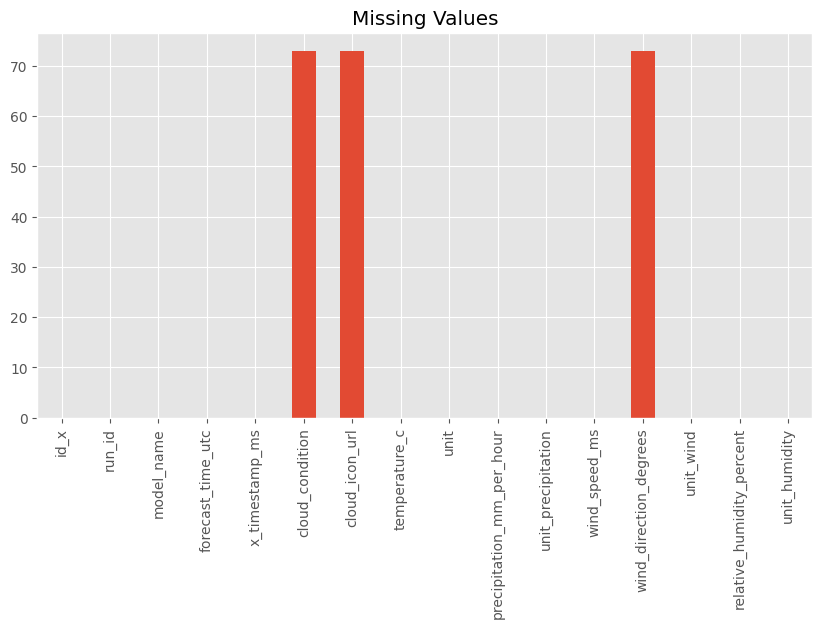

In [26]:
missing = df.isnull().sum()

print(missing)

missing.plot(kind="bar", figsize=(10,5))
plt.title("Missing Values")
plt.show()

# Duplicate Records

In [27]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [29]:
print(df["model_name"].value_counts())

model_name
AIFS025         73
Ensemble        73
GEM15           73
GFS05           73
ICON            73
IFS025          73
IFSHRES         73
MFGLOBAL        73
NEMSGLOBAL      73
NEMSGLOBAL_E    73
NEMSIN          73
UMGLOBAL10      73
Name: count, dtype: int64


In [31]:
df["forecast_time_utc"] = pd.to_datetime(df["forecast_time_utc"])

print(df["forecast_time_utc"].min())
print(df["forecast_time_utc"].max())

2026-06-24 00:00:00+00:00
2026-06-27 00:00:00+00:00


# Temperature Analysis

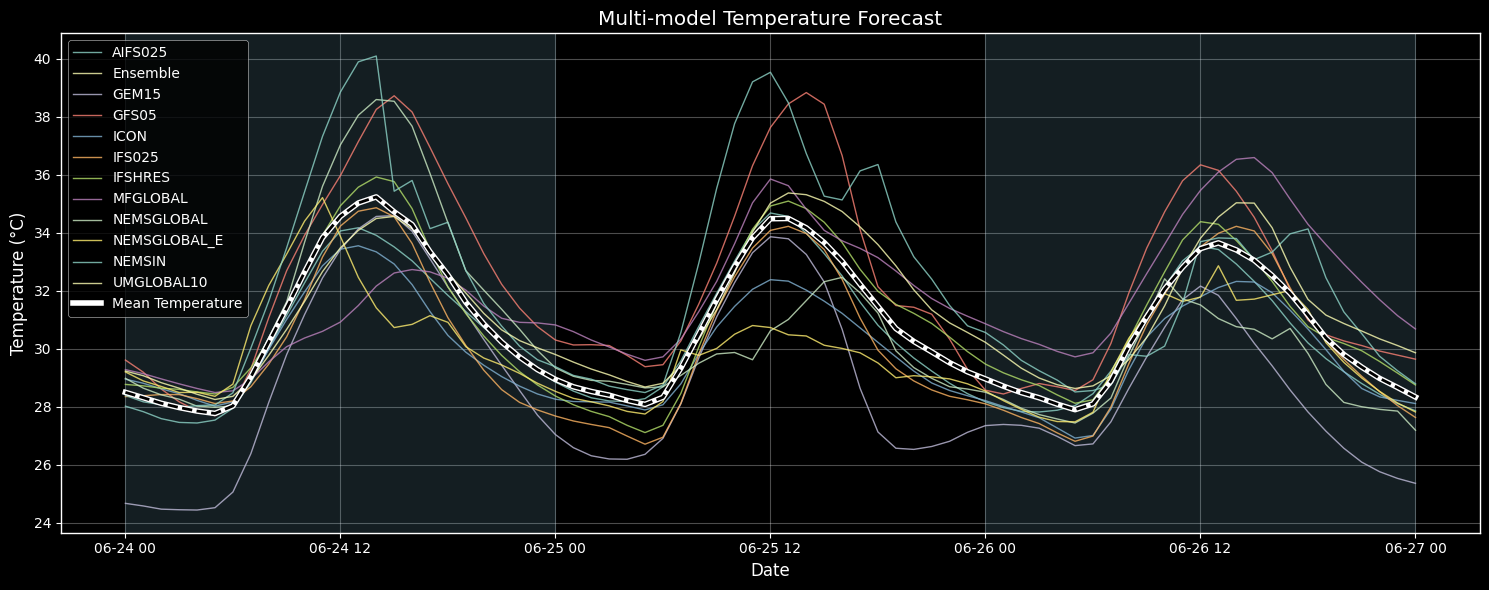

In [36]:

plt.style.use("dark_background")

plt.figure(figsize=(15,6))

# Get unique model names to plot each one
unique_models = df["model_name"].unique()

# Plot each model's temperature forecast
for model in unique_models:
    model_df = df[df["model_name"] == model]
    plt.plot(model_df["forecast_time_utc"], model_df["temperature_c"],
             linewidth=1,
             alpha=0.8,
             label=model)

# Calculate and plot the average forecast
# Group by forecast_time_utc and calculate the mean of temperature_c
mean_temp_df = df.groupby("forecast_time_utc")["temperature_c"].mean().reset_index()

plt.plot(mean_temp_df["forecast_time_utc"],
         mean_temp_df["temperature_c"],
         color="white",
         linewidth=4,
         label="Mean Temperature")

# Optional dashed line (for mean)
plt.plot(mean_temp_df["forecast_time_utc"],
         mean_temp_df["temperature_c"],
         "--",
         color="black",
         linewidth=2)

# Shade every other day
days = df["forecast_time_utc"].dt.normalize().unique()

for i, day in enumerate(days):
    if i % 2 == 0:
        plt.axvspan(day,
                    day + pd.Timedelta(days=1),
                    color="skyblue",
                    alpha=0.15)

plt.grid(alpha=0.3)
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Multi-model Temperature Forecast")
plt.legend()
plt.tight_layout()

plt.show()

# Rainfall Analysis

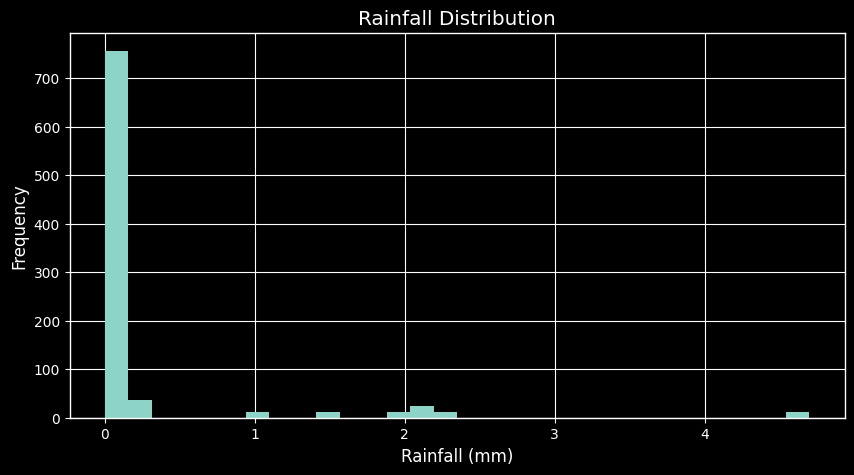

In [44]:
plt.figure(figsize=(10,5))

plt.hist(df["precipitation_mm_per_hour"], bins=30)

plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")

plt.title("Rainfall Distribution")

plt.show()

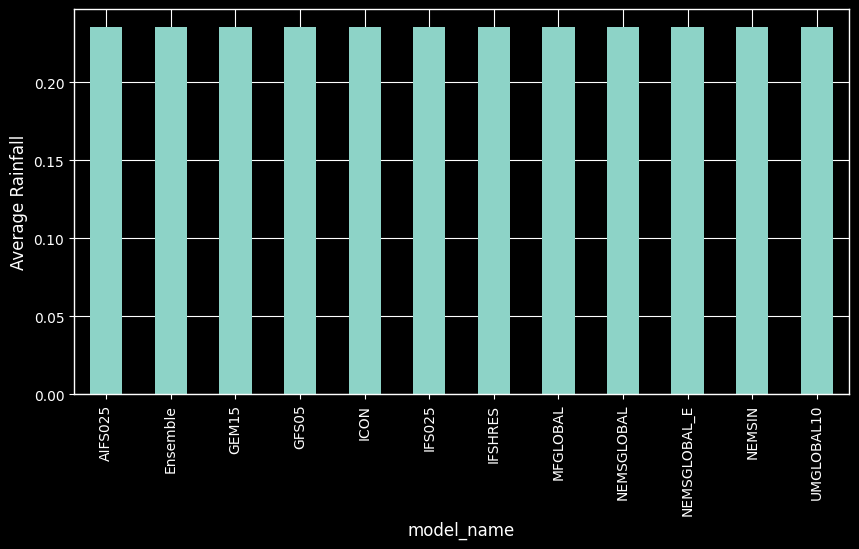

In [46]:
rain = df.groupby("model_name")["precipitation_mm_per_hour"].mean()

rain.sort_values().plot(kind="bar", figsize=(10,5))

plt.ylabel("Average Rainfall")

plt.show()

# Wind Analysis

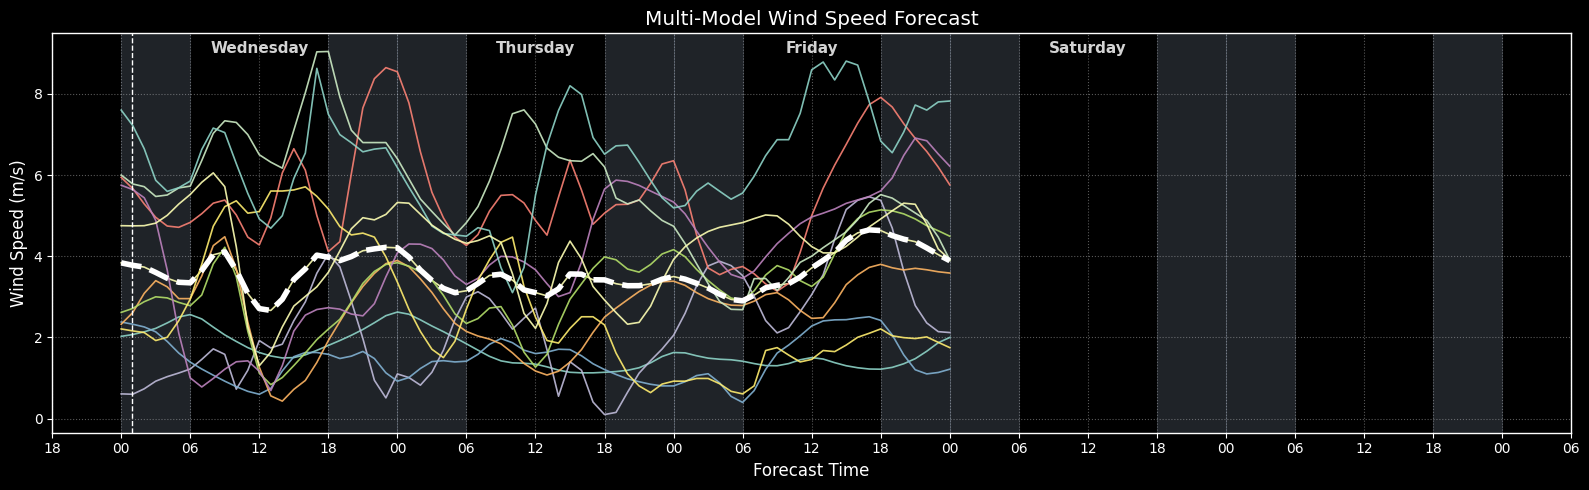

In [60]:
import matplotlib.dates as mdates

plt.style.use("dark_background")

# Convert to datetime
df["forecast_time_utc"] = pd.to_datetime(df["forecast_time_utc"])

# Sort data
df = df.sort_values("forecast_time_utc")

fig, ax = plt.subplots(figsize=(16,5))

# Background shading (night: 00-06 and 18-24)
days = pd.date_range(
    df["forecast_time_utc"].min().normalize(),
    df["forecast_time_utc"].max().normalize() + pd.Timedelta(days=1),
    freq="D"
)

for d in days:
    ax.axvspan(d,
               d + pd.Timedelta(hours=6),
               color="lightsteelblue",
               alpha=0.18)

    ax.axvspan(d + pd.Timedelta(hours=18),
               d + pd.Timedelta(days=1),
               color="lightsteelblue",
               alpha=0.18)

# Plot each model
models = sorted(df["model_name"].unique())

for model in models:
    temp = df[df["model_name"] == model]

    ax.plot(
        temp["forecast_time_utc"],
        temp["wind_speed_ms"],
        linewidth=1.2,
        alpha=0.9,
        label=model
    )

# Average (ensemble) line
avg = (
    df.groupby("forecast_time_utc")["wind_speed_ms"]
      .mean()
      .reset_index()
)

ax.plot(
    avg["forecast_time_utc"],
    avg["wind_speed_ms"],
    color="white",
    linewidth=4,
    linestyle="--",
    label="Average"
)

# Current time
ax.axvline(
    pd.Timestamp.now(),
    color="white",
    linestyle="--",
    linewidth=1
)

# Formatting
ax.set_ylabel("Wind Speed (m/s)", fontsize=12)
ax.set_xlabel("Forecast Time")

ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))

# Day names
ymax = ax.get_ylim()[1]

for d in days[:-1]:
    ax.text(
        d + pd.Timedelta(hours=12),
        ymax * 0.98,
        d.strftime("%A"),
        ha="center",
        va="top",
        fontsize=11,
        weight="bold",
        color="lightgray"
    )

ax.grid(True, linestyle=":", alpha=0.35)

plt.title("Multi-Model Wind Speed Forecast")
plt.tight_layout()
plt.show()

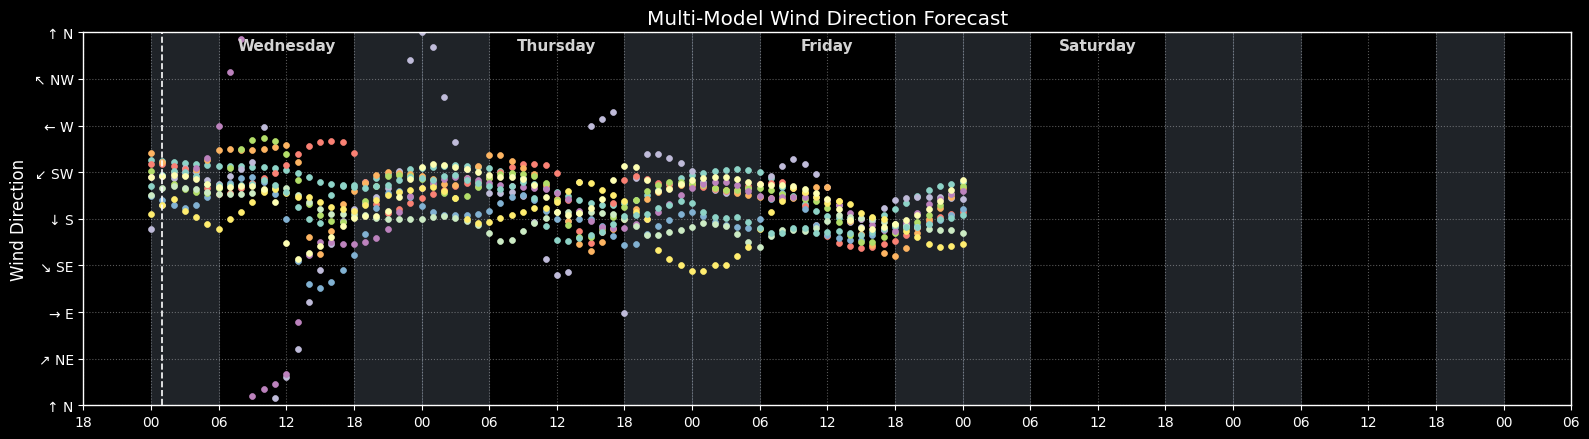

In [59]:
plt.style.use("dark_background")

df["forecast_time_utc"] = pd.to_datetime(df["forecast_time_utc"])

fig, ax = plt.subplots(figsize=(16,4.5))

# Night shading
days = pd.date_range(
    df["forecast_time_utc"].min().normalize(),
    df["forecast_time_utc"].max().normalize() + pd.Timedelta(days=1),
    freq="D"
)

for d in days:
    ax.axvspan(d,
               d + pd.Timedelta(hours=6),
               color="lightsteelblue",
               alpha=0.18)

    ax.axvspan(d + pd.Timedelta(hours=18),
               d + pd.Timedelta(days=1),
               color="lightsteelblue",
               alpha=0.18)

# Plot each model
models = sorted(df["model_name"].unique())

for model in models:
    temp = df[df["model_name"] == model]

    ax.scatter(
        temp["forecast_time_utc"],
        temp["wind_direction_degrees"],
        s=18,
        label=model
    )

# Current time
ax.axvline(
    pd.Timestamp.now(),
    color="white",
    linestyle="--",
    linewidth=1.2
)

# Compass labels
ticks = [0,45,90,135,180,225,270,315,360]
labels = ['↑ N','↗ NE','→ E','↘ SE','↓ S','↙ SW','← W','↖ NW','↑ N']

ax.set_yticks(ticks)
ax.set_yticklabels(labels)

# Time axis
ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

# Day names
for d in days[:-1]:
    ax.text(
        d + pd.Timedelta(hours=12),
        355,
        d.strftime("%A"),
        ha='center',
        va='top',
        fontsize=11,
        fontweight='bold',
        color="lightgray"
    )

ax.set_ylim(0,360)
ax.set_ylabel("Wind Direction")

ax.grid(True, linestyle=":", alpha=0.35)

plt.title("Multi-Model Wind Direction Forecast")

plt.tight_layout()
plt.show()

# Relative Humidity

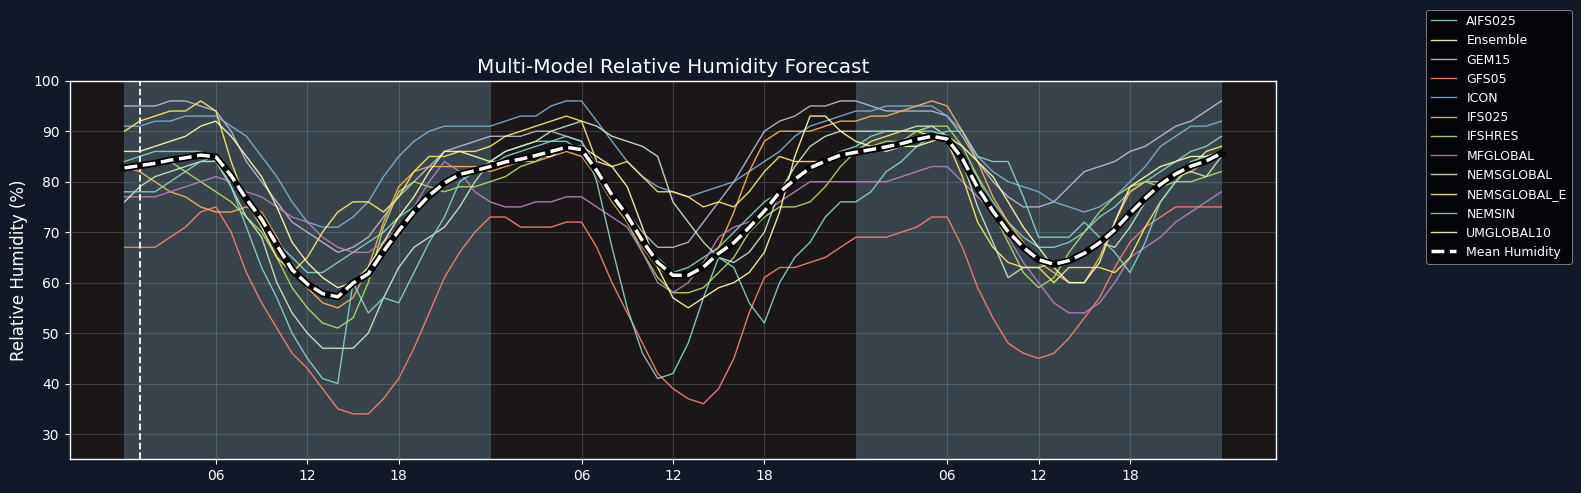

In [63]:

plt.style.use("dark_background")

fig, ax = plt.subplots(figsize=(16,5))

# Convert forecast_time_utc to datetime if not already done (for robustness)
df["forecast_time_utc"] = pd.to_datetime(df["forecast_time_utc"])

# Plot every weather model
unique_models = sorted(df["model_name"].unique())

for model in unique_models:
    model_df = df[df["model_name"] == model]
    ax.plot(model_df["forecast_time_utc"],
            model_df["relative_humidity_percent"],
            lw=1,
            alpha=0.9,
            label=model)

# Ensemble mean
mean_humidity_df = df.groupby("forecast_time_utc")["relative_humidity_percent"].mean().reset_index()

ax.plot(mean_humidity_df["forecast_time_utc"],
        mean_humidity_df["relative_humidity_percent"],
        color="black",
        lw=5,
        zorder=10)

ax.plot(mean_humidity_df["forecast_time_utc"],
        mean_humidity_df["relative_humidity_percent"],
        color="white",
        lw=2.5,
        ls="--",
        zorder=11,
        label="Mean Humidity")

# Shade alternate days
days = pd.date_range(df["forecast_time_utc"].min().normalize(),
                     df["forecast_time_utc"].max().normalize() + pd.Timedelta(days=1),
                     freq="D")

for i in range(len(days)-1):
    if i % 2 == 0:
        ax.axvspan(days[i],
                   days[i+1],
                   color="#8fc7e8",
                   alpha=0.25)

# Current time
ax.axvline(pd.Timestamp.now(),
           color="white",
           ls="--",
           lw=1.3)

# Axis formatting
ax.set_ylim(25,100)

ax.set_ylabel("Relative Humidity (%)",
              fontsize=12)

ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[6,12,18]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))

ax.grid(True,
        color="gray",
        alpha=.35)

ax.set_facecolor("#1b1719")
fig.patch.set_facecolor("#111827")

plt.legend(loc='lower right', bbox_to_anchor=(1.25, 0.5), fontsize=9)
plt.title("Multi-Model Relative Humidity Forecast")
plt.tight_layout()
plt.show()

# Meteoblue MultiModel Weather Icon Chart

In [84]:
# Upload the CSV (run this only in Colab)
import sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import files
    print('Please upload clean_meteoblue_forecast.csv')
    uploaded = files.upload()
    CSV_PATH = list(uploaded.keys())[0]
else:
    CSV_PATH = 'clean_meteoblue_forecast.csv'   # adjust if running locally

print(f' Using file: {CSV_PATH}')

Please upload clean_meteoblue_forecast.csv


Saving clean_meteoblue_forecast.csv to clean_meteoblue_forecast (2).csv
 Using file: clean_meteoblue_forecast (2).csv


In [85]:
import pandas as pd
import numpy as np
from IPython.display import display, HTML
import warnings
warnings.filterwarnings('ignore')

# Load
df = pd.read_csv(CSV_PATH, parse_dates=['forecast_time_utc'])

# Convert UTC → IST (UTC+5:30)
df['forecast_time_ist'] = df['forecast_time_utc'] + pd.Timedelta(hours=5, minutes=30)
df['date']  = df['forecast_time_ist'].dt.date
df['hour']  = df['forecast_time_ist'].dt.strftime('%H:%M')

# Clean cloud_icon_url — strip CSS url() wrapper
df['icon_url'] = df['cloud_icon_url'].str.extract(r'url\((.+?)\)')

# Friendly model display names
MODEL_LABELS = {
    'AIFS025':      'AIFS-25',
    'GEM15':        'GEM-15',
    'GFS05':        'GFS-40',
    'ICON':         'ICON-12',
    'IFS025':       'IFS-20',
    'IFSHRES':      'IFS-HRES',
    'MFGLOBAL':     'ARPEGE-25',
    'NEMSGLOBAL':   'NEMS-30',
    'NEMSGLOBAL_E': 'NEMS2-30',
    'NEMSIN':       'NEMS-10',
    'UMGLOBAL10':   'UKMO-10',
    'Ensemble':     'Ensemble',
}
df['model_label'] = df['model_name'].map(MODEL_LABELS).fillna(df['model_name'])

print(f'✅ Loaded {len(df):,} rows')
print(f'   Models : {sorted(df["model_label"].unique())}')
print(f'   Dates  : {sorted(df["date"].astype(str).unique())}')
df.head(3)

✅ Loaded 876 rows
   Models : ['AIFS-25', 'ARPEGE-25', 'Ensemble', 'GEM-15', 'GFS-40', 'ICON-12', 'IFS-20', 'IFS-HRES', 'NEMS-10', 'NEMS-30', 'NEMS2-30', 'UKMO-10']
   Dates  : ['2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27']


,model_name,forecast_time_utc,x_timestamp_ms,temperature_c,precipitation_mm_per_hour,wind_speed_ms,wind_direction_degrees,relative_humidity_percent,cloud_condition,cloud_icon_url,precip_model_name,forecast_time_ist,date,hour,icon_url,model_label
0,AIFS025,2026-06-24 00:00:00+00:00,1782259200000,28.02,1.4656,2.0251,237.0,84.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement,2026-06-24 05:30:00+00:00,2026-06-24,05:30,https://my.meteoblue.com/images/static/meteobl...,AIFS-25
1,AIFS025,2026-06-24 01:00:00+00:00,1782262800000,27.83,0.0000,2.0698,236.0,85.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement,2026-06-24 06:30:00+00:00,2026-06-24,06:30,https://my.meteoblue.com/images/static/meteobl...,AIFS-25
2,AIFS025,2026-06-24 02:00:00+00:00,1782266400000,27.59,0.0000,2.1369,235.0,86.0,Cloudy (Night),url(https://my.meteoblue.com/images/static/met...,Models agreement,2026-06-24 07:30:00+00:00,2026-06-24,07:30,https://my.meteoblue.com/images/static/meteobl...,AIFS-25


In [86]:
#  Select date
available_dates = sorted(df['date'].astype(str).unique())
print('Available dates:', available_dates)

SELECTED_DATE = available_dates[0]   # ← change to any date in the list

# Select models (None = all)
SELECTED_MODELS = None  # or e.g. ['AIFS-25', 'GFS-40', 'ICON-12', 'UKMO-10']

#  Hour range (IST)
HOUR_START = 0   # 0–23
HOUR_END   = 23

# Apply filters
mask = (df['date'].astype(str) == SELECTED_DATE) & \
       (df['forecast_time_ist'].dt.hour >= HOUR_START) & \
       (df['forecast_time_ist'].dt.hour <= HOUR_END)

if SELECTED_MODELS:
    mask &= df['model_label'].isin(SELECTED_MODELS)

dff = df[mask].copy()
print(f'\n✅ Filtered to {len(dff)} rows for {SELECTED_DATE}')

Available dates: ['2026-06-24', '2026-06-25', '2026-06-26', '2026-06-27']

✅ Filtered to 228 rows for 2026-06-24


In [87]:
def render_pictogram_table(dff, icon_size=32):
    """Render a Model × Hour pictogram table like the Meteoblue website."""

    hours  = sorted(dff['hour'].unique())
    models = dff['model_label'].unique()   # keep insertion order (original order in CSV)

    #  HTML header
    css = """
    <style>
      .mb-table { border-collapse: collapse; font-family: 'Segoe UI', Arial, sans-serif;
                  font-size: 11px; background:#1a1a2e; color:#e0e0e0; width:100%; }
      .mb-table th { background:#16213e; color:#a0c4ff; padding:4px 6px;
                     text-align:center; border:1px solid #2d3561; white-space:nowrap; }
      .mb-table td { border:1px solid #2d3561; padding:2px 4px;
                     text-align:center; vertical-align:middle; }
      .mb-table tr:hover td { background:#243b6e55; }
      .model-name { font-weight:bold; color:#a0c4ff; text-align:left !important;
                    padding-left:8px !important; white-space:nowrap; min-width:90px; }
      .hour-hdr { font-size:10px; min-width:36px; }
      .night-cell { background:#12122a; }
      .day-cell   { background:#1a1a38; }
      .picto img  { display:block; margin:auto; }
      .tip        { font-size:9px; color:#8090a0; display:block; }
      .sticky-col { position:sticky; left:0; z-index:2; background:#16213e !important; }
      .scroll-wrap { overflow-x:auto; max-height:520px; }
    </style>
    """

    rows = [css,
            f'<h3 style="font-family:sans-serif;color:#a0c4ff">'
            f'🌦 Meteoblue Multimodel — Chandīpur &nbsp;|&nbsp; {SELECTED_DATE} (IST)</h3>',
            '<div class="scroll-wrap"><table class="mb-table"><thead><tr>',
            '<th class="sticky-col" style="min-width:90px">Model</th>']

    for h in hours:
        hr = int(h.split(':')[0])
        rows.append(f'<th class="hour-hdr">{h}</th>')

    rows.append('</tr></thead><tbody>')

    for model in models:
        mdf = dff[dff['model_label'] == model].set_index('hour')
        rows.append(f'<tr><td class="model-name sticky-col">{model}</td>')
        for h in hours:
            hr = int(h.split(':')[0])
            cell_cls = 'night-cell' if (hr < 6 or hr >= 19) else 'day-cell'
            if h in mdf.index:
                row = mdf.loc[h]
                icon = row['icon_url'] if pd.notna(row['icon_url']) else ''
                cond = row['cloud_condition'] if pd.notna(row['cloud_condition']) else ''
                short = cond.replace(' (Night)','').replace(' (Day)','')
                if icon:
                    cell = (f'<div class="picto">'
                            f'<img src="{icon}" width="{icon_size}" height="{icon_size}" '
                            f'title="{cond}"/>'
                            f'<span class="tip">{short[:10]}</span></div>')
                else:
                    cell = f'<span title="{cond}">{short[:8]}</span>'
            else:
                cell = '<span style="color:#444">—</span>'
            rows.append(f'<td class="{cell_cls}">{cell}</td>')
        rows.append('</tr>')

    rows.append('</tbody></table></div>')
    return ''.join(rows)

display(HTML(render_pictogram_table(dff, icon_size=34)))

Model,05:30,06:30,07:30,08:30,09:30,10:30,11:30,12:30,13:30,14:30,15:30,16:30,17:30,18:30,19:30,20:30,21:30,22:30,23:30
AIFS-25,Cloudy,Cloudy,Cloudy,Cloudy,Cloudy,Cloudy,Cloudy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy
Ensemble,,,,,,,,,,,,,,,,,,,
GEM-15,Cloudy,Cloudy,Cloudy,Cloudy,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo,Mainly sun,Mainly sun,Mainly sun,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo
GFS-40,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast
ICON-12,Partly clo,Partly clo,Partly clo,Partly clo,Overcast,Overcast,Overcast,Partly clo,Partly clo,Partly clo,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy
IFS-20,Partly clo,Partly clo,Partly clo,Partly clo,Mainly cle,Mainly cle,Mainly cle,Mainly sun,Mainly sun,Mainly sun,Mainly sun,Mainly sun,Mainly sun,Rainy,Rainy,Rainy,Rainy,Rainy,Rainy
IFS-HRES,Overcast,Overcast,Overcast,Overcast,Mainly cle,Mainly cle,Mainly cle,Mainly sun,Mainly sun,Mainly sun,Mainly sun,Mainly sun,Mainly sun,Sunny,Sunny,Sunny,Rainy,Rainy,Rainy
ARPEGE-25,Mainly cle,Mainly cle,Mainly cle,Mainly cle,Mainly cle,Mainly cle,Mainly cle,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo,Partly clo,Sunny,Sunny,Sunny
NEMS-30,Cloudy,Cloudy,Cloudy,Cloudy,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast
NEMS2-30,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Overcast,Cloudy,Cloudy,Cloudy,Showers,Showers,Showers,Overcast,Overcast,Overcast
